In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import random
import sys

sys.path.append("../../../mapqc/")
import mapqc
import plotting

In [2]:
%load_ext lab_black
%load_ext autoreload
%autoreload 2

In [3]:
query_batch = "Thienpont_2018_10Xv2"

In [4]:
kl_parameter = 1

In [5]:
dir_mapped_results = f"./{query_batch}_kl{kl_parameter}_sample_as_batch"

In [6]:
adata = sc.read_h5ad(
    f"{dir_mapped_results}/combined_embedding_klweight_{kl_parameter}.h5ad"
)

clean up/add annotations:

In [7]:
subject_to_cancertype = {
    "lambrechts_1": "Squamous Cell Carcinoma",
    "lambrechts_2": "Squamous Cell Carcinoma",
    "lambrechts_3": "Adenocarcinoma",
    "lambrechts_4": "Adenocarcinoma",
    "lambrechts_5": "Large Cell Carcinoma",
    "lambrechts_6": "Adenocarcinoma",
    "lambrechts_7": "Squamous Cell Carcinoma",
    "lambrechts_8": "Pleiomorphic Carcinoma",
}
adata.obs["cancer_type"] = adata.obs.subject_ID.map(subject_to_cancertype)
site_acr_to_site = {
    "I": "Tumor (inner)",
    "M": "Tumor (middle)",
    "O": "Tumor (outer)",
    "U": "Unknown",
    "N": "Normal",
}
adata.obs["tumor_site"] = adata.obs.tumor_site.map(site_acr_to_site)

In [8]:
ref_q_key = "core_or_extension"
ref_cat = "core"
query_cat = "extension"
batch_key = "dataset"
sample_key = "sample"
condition_key = "lung_condition"
coi_healthy = "Healthy (tumor adjacent)"
coi_disease = "Tumor"
emb_key = "X"

In [9]:
adata.obs.loc[adata.obs[ref_q_key] == query_cat, condition_key].unique()

['Tumor', 'Healthy (tumor adjacent)']
Categories (3, object): ['Healthy', 'Healthy (tumor adjacent)', 'Tumor']

In [10]:
adata

AnnData object with n_obs × n_vars = 678519 × 30
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', 'tis

OPTIONAL: REMOVE PLEIMORPHIC CARCINOMA FROM THE DATA BASED ON RESULTS FROM HEALTHY MAPPING:

In [11]:
print(
    "Removing Pleiomorphic Carcinoma samples from data, as these did not map well. We should ideally re-calculate the UMAP at this point!"
)
adata = adata[adata.obs.cancer_type != "Pleiomorphic Carcinoma", :].copy()

Removing Pleiomorphic Carcinoma samples from data, as these did not map well. We should ideally re-calculate the UMAP at this point!


In [12]:
print(f"Subsetting query to condition {coi_healthy}")
adata_healthy = adata[
    (adata.obs[ref_q_key] == ref_cat) | (adata.obs[condition_key] == coi_healthy)
].copy()

Subsetting query to condition Healthy (tumor adjacent)


In [13]:
print(
    "number of query samples left:",
    len(
        adata_healthy.obs.loc[
            adata_healthy.obs[ref_q_key] == query_cat, "sample"
        ].unique()
    ),
)

number of query samples left: 6


In [14]:
adata.shape

(667754, 30)

In [15]:
adata_healthy.shape

(609033, 30)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


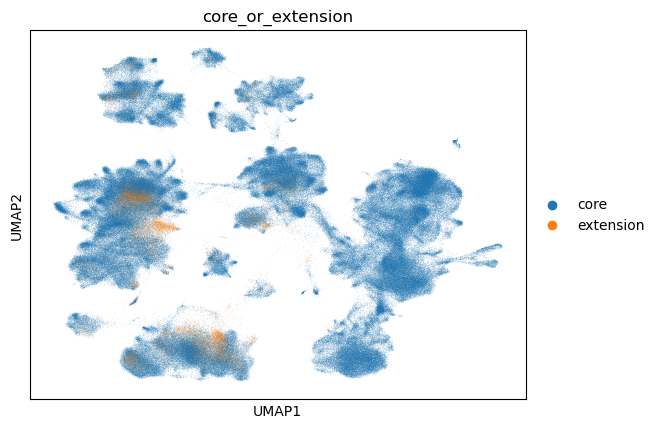

In [16]:
sc.pl.umap(adata_healthy, color=ref_q_key)

#### run MapQC:

In [17]:
n_nhoods = 300
k = int((adata.obs[ref_q_key] == ref_cat).sum() / 200)
max_k = int(k * 1.2)

In [18]:
print(f"k: {k}, max k: {max_k}")

k: 2924, max k: 3508


In [19]:
query_cell_idc_healthy = np.where(adata_healthy.obs[ref_q_key] == query_cat)[0].tolist()
random.seed(0)
center_cell_idc_healthy = random.sample(query_cell_idc_healthy, k=n_nhoods)
center_cells_healthy = np.array(
    adata_healthy.obs.iloc[center_cell_idc_healthy, :].index
)

In [20]:
results_healthy = mapqc.mapQC_results(
    adata=adata_healthy,
    center_cells=center_cells_healthy,
    k=k,
    emb_key=emb_key,
    ref_q_key=ref_q_key,
    ref_cat=ref_cat,
    query_cat=query_cat,
    batch_key=batch_key,
    exclude_same_batch_for_ref_samples=True,
    use_adaptive_k=True,
    max_k=max_k,
    min_n_cells_per_sample=10
    # min_n_samples_q=1 # NOTE THAT THIS IS NOT THE DEFAULT...
)

In [21]:
results_healthy.calculate_sample_dists_to_ref_samples()

300it [02:19,  2.15it/s]

93% of neighborhoods passed filtering. (For more details, see [mapqc_object]._nhood_filtered)



../../../mapqc/mapqc.py:199: RuntimeWarning: Mean of empty slice
  self.mean_sample_dists_to_ref = np.nanmean(self.intersample_distances, axis=0)
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1577: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,
../../../mapqc/mapqc.py:224: RuntimeWarning: Mean of empty slice
  nhood_ref_mean_dists = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1872: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [22]:
results_healthy._nhood_filtered.value_counts()

pass                     278
too few query samples     22
dtype: int64

In [23]:
results_healthy.calculate_nhood_statistics(q=66)

1% of neighborhoods that passed filtering are below the significance threshold alpha=0.05.
For 10% of filtered neighborhoods, >34% of samples are more than two standard deviations above the mean distance from the reference.
0% of query samples (0 sample(s)) consistently do not mix well with the reference.


../../../mapqc/mapqc.py:364: RuntimeWarning: Mean of empty slice
  mean_zscored_q_dist_to_ref = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1217: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a, func=_nanmedian, keepdims=keepdims,
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1577: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,


In [25]:
results_healthy.calculate_cell_statistics_using_sample_level_results_per_nhood()

Percentage of query cells showing low sample-mixing: 9.75.


### Plot

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


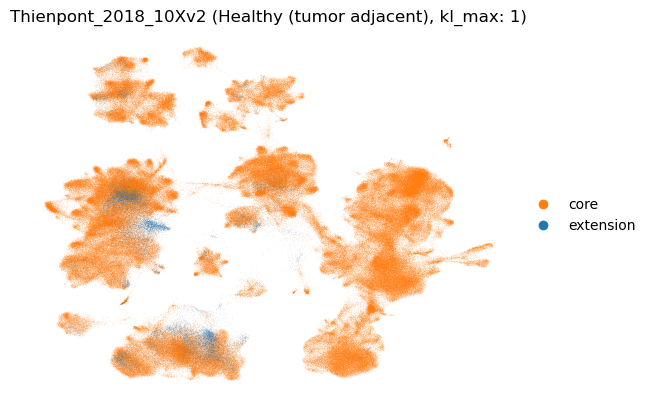

In [26]:
sc.pl.umap(
    results_healthy.adata,
    color=ref_q_key,
    palette={
        results_healthy.ref_cat: "tab:orange",
        results_healthy.query_cat: "tab:blue",
    },
    title=f"{query_batch} ({coi_healthy}, kl_max: {kl_parameter})",
    frameon=False,
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


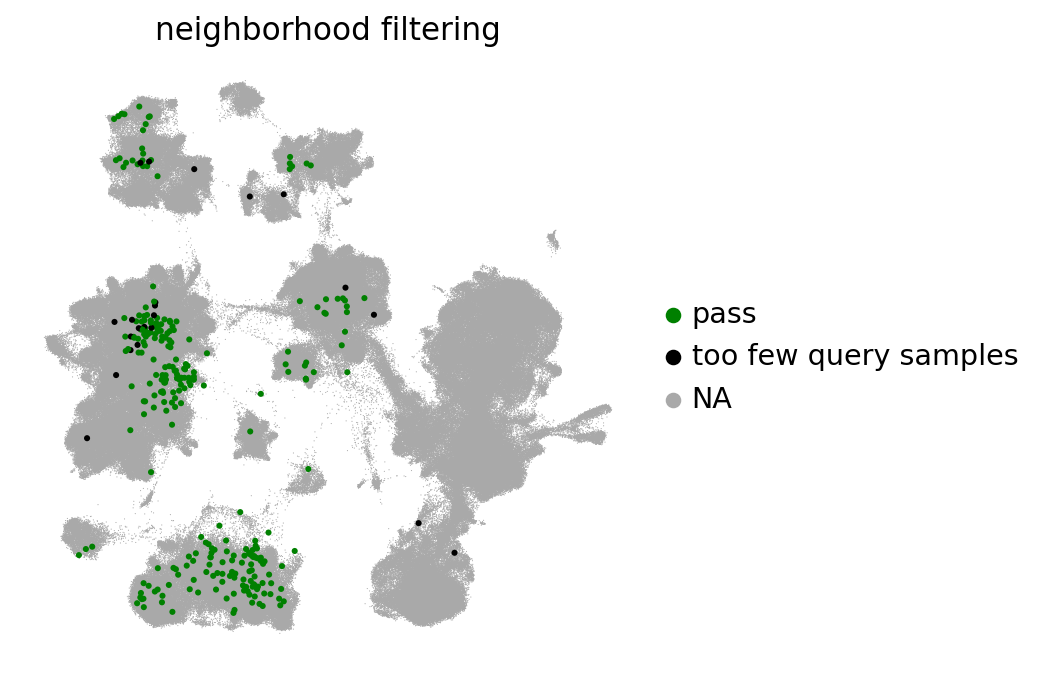

In [27]:
plotting.plot_umap_filtering_info(results_healthy)

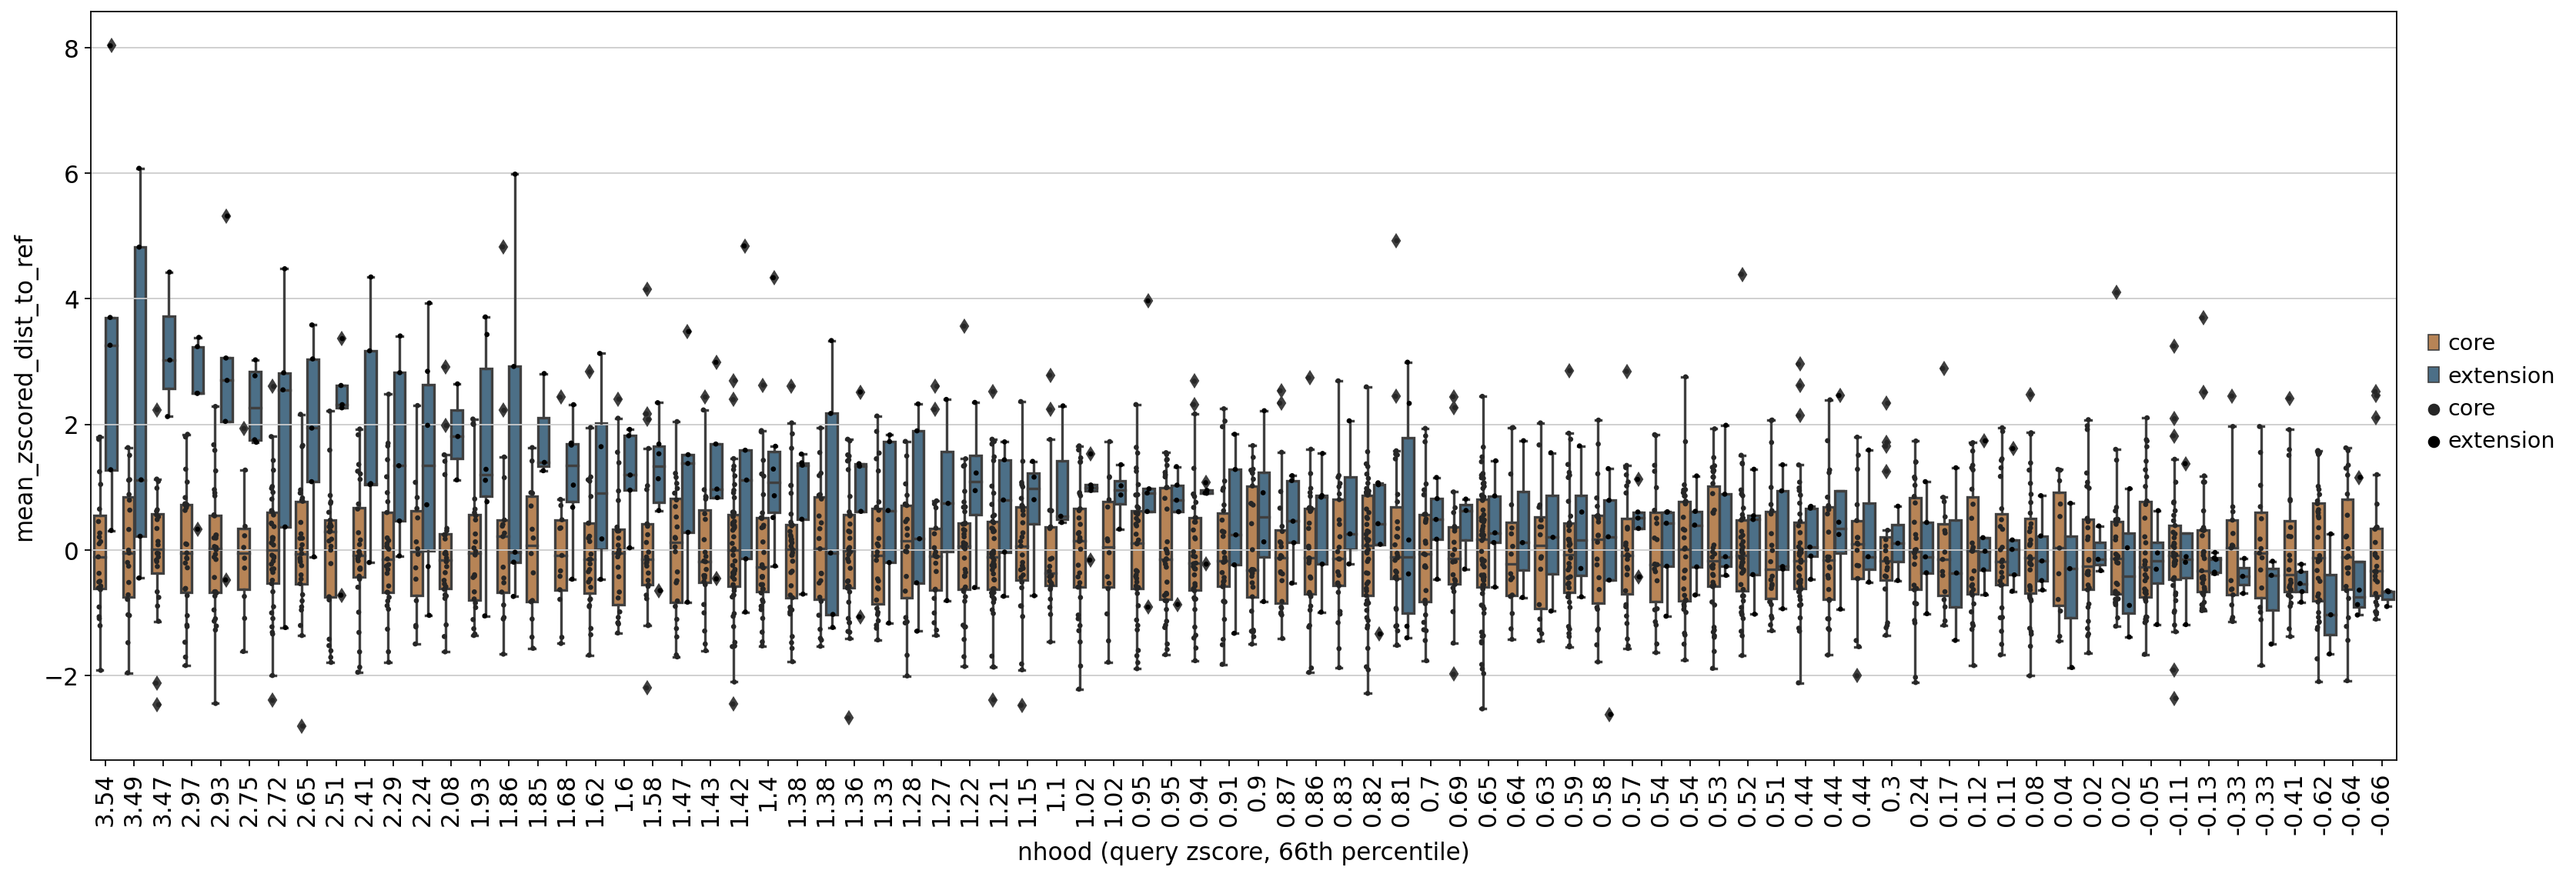

In [28]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(
    results_healthy, use_zscored_dists=True
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


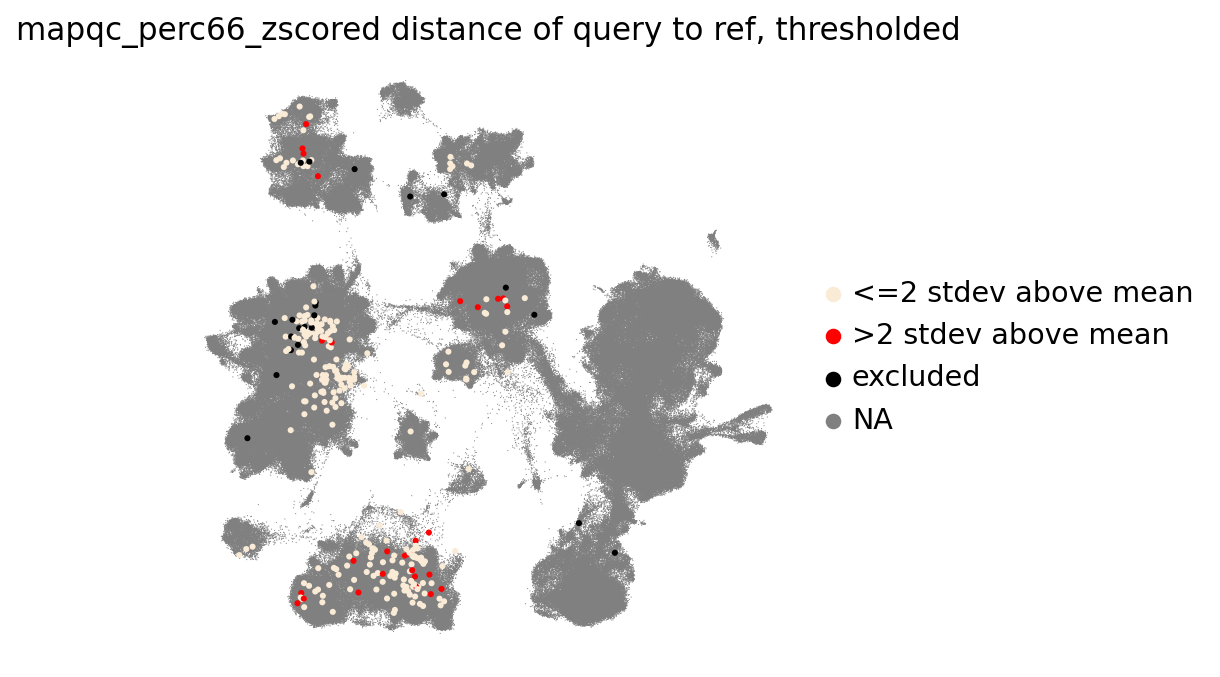

In [29]:
plotting.plot_umap_zscored_q_dist_to_ref(results_healthy, color_by="percq_zscore>2")

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


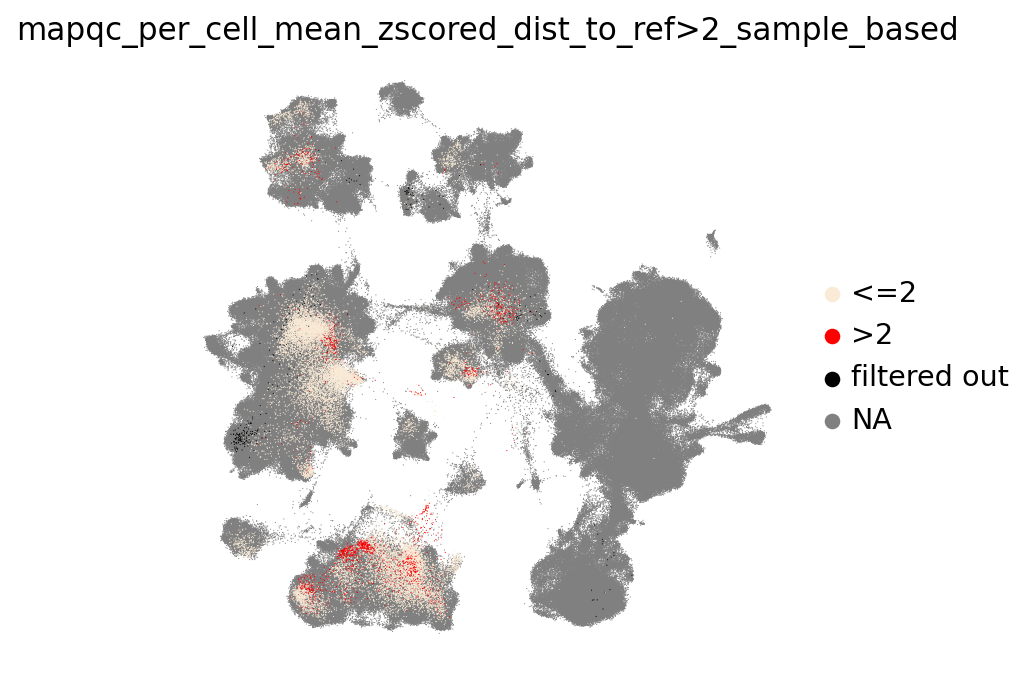

In [30]:
plotting.plot_umap_cell_level_results(results_healthy, size=1)

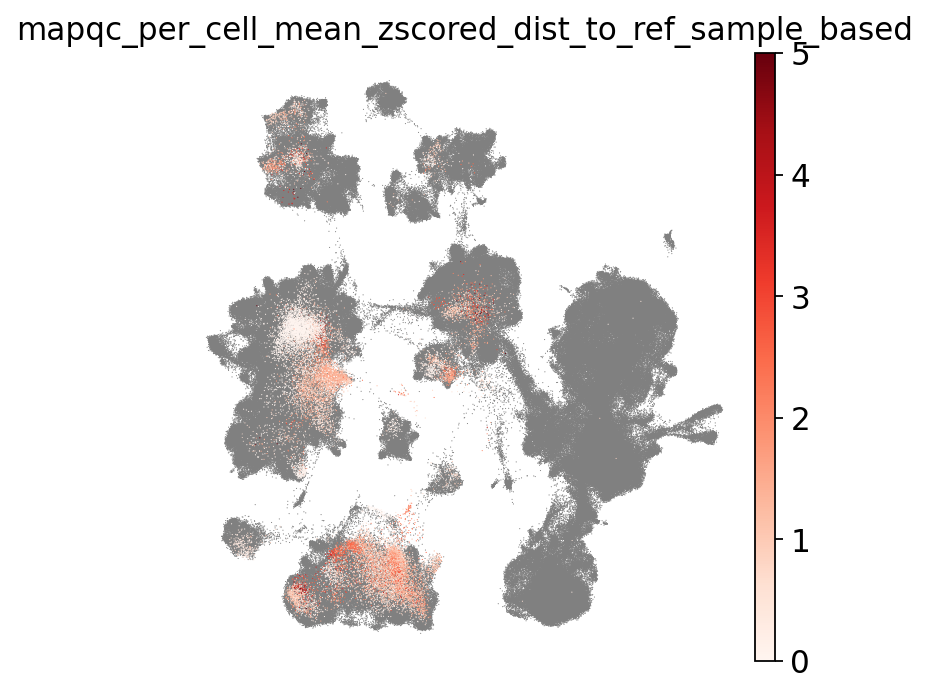

In [31]:
plotting.plot_umap_cell_level_results(
    results_healthy, size=1, color_by="zscore", vmin=0, vmax=5
)

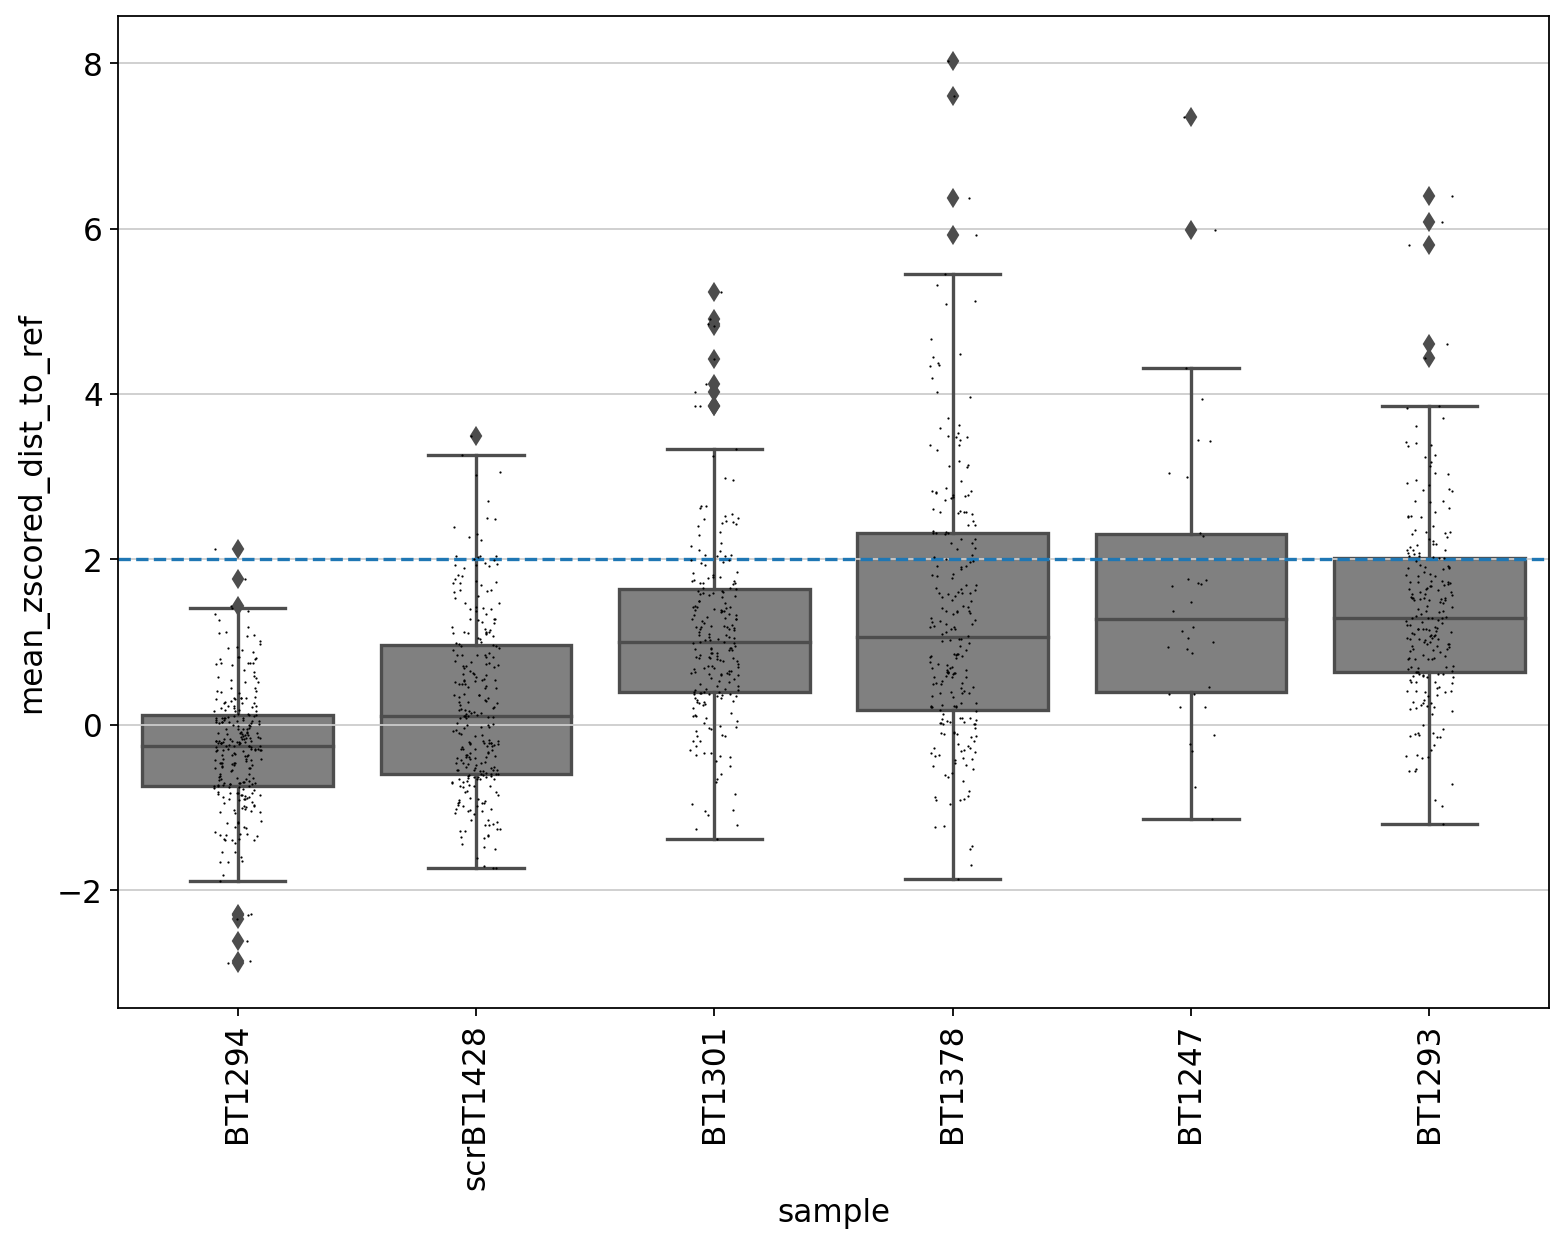

In [33]:
plotting.plot_sample_distances_to_reference(results_healthy)

In [34]:
results_healthy.adata.obs.groupby("sample").agg(
    {"cancer_type": "first", "subject_ID": "first"} # add mean zscored dist to ref here
).dropna(axis=0, how="any")

,cancer_type,subject_ID
sample,,
BT1247,Squamous Cell Carcinoma,lambrechts_2
BT1293,Adenocarcinoma,lambrechts_3
BT1294,Adenocarcinoma,lambrechts_4
BT1301,Large Cell Carcinoma,lambrechts_5
BT1378,Adenocarcinoma,lambrechts_6
scrBT1428,Squamous Cell Carcinoma,lambrechts_7


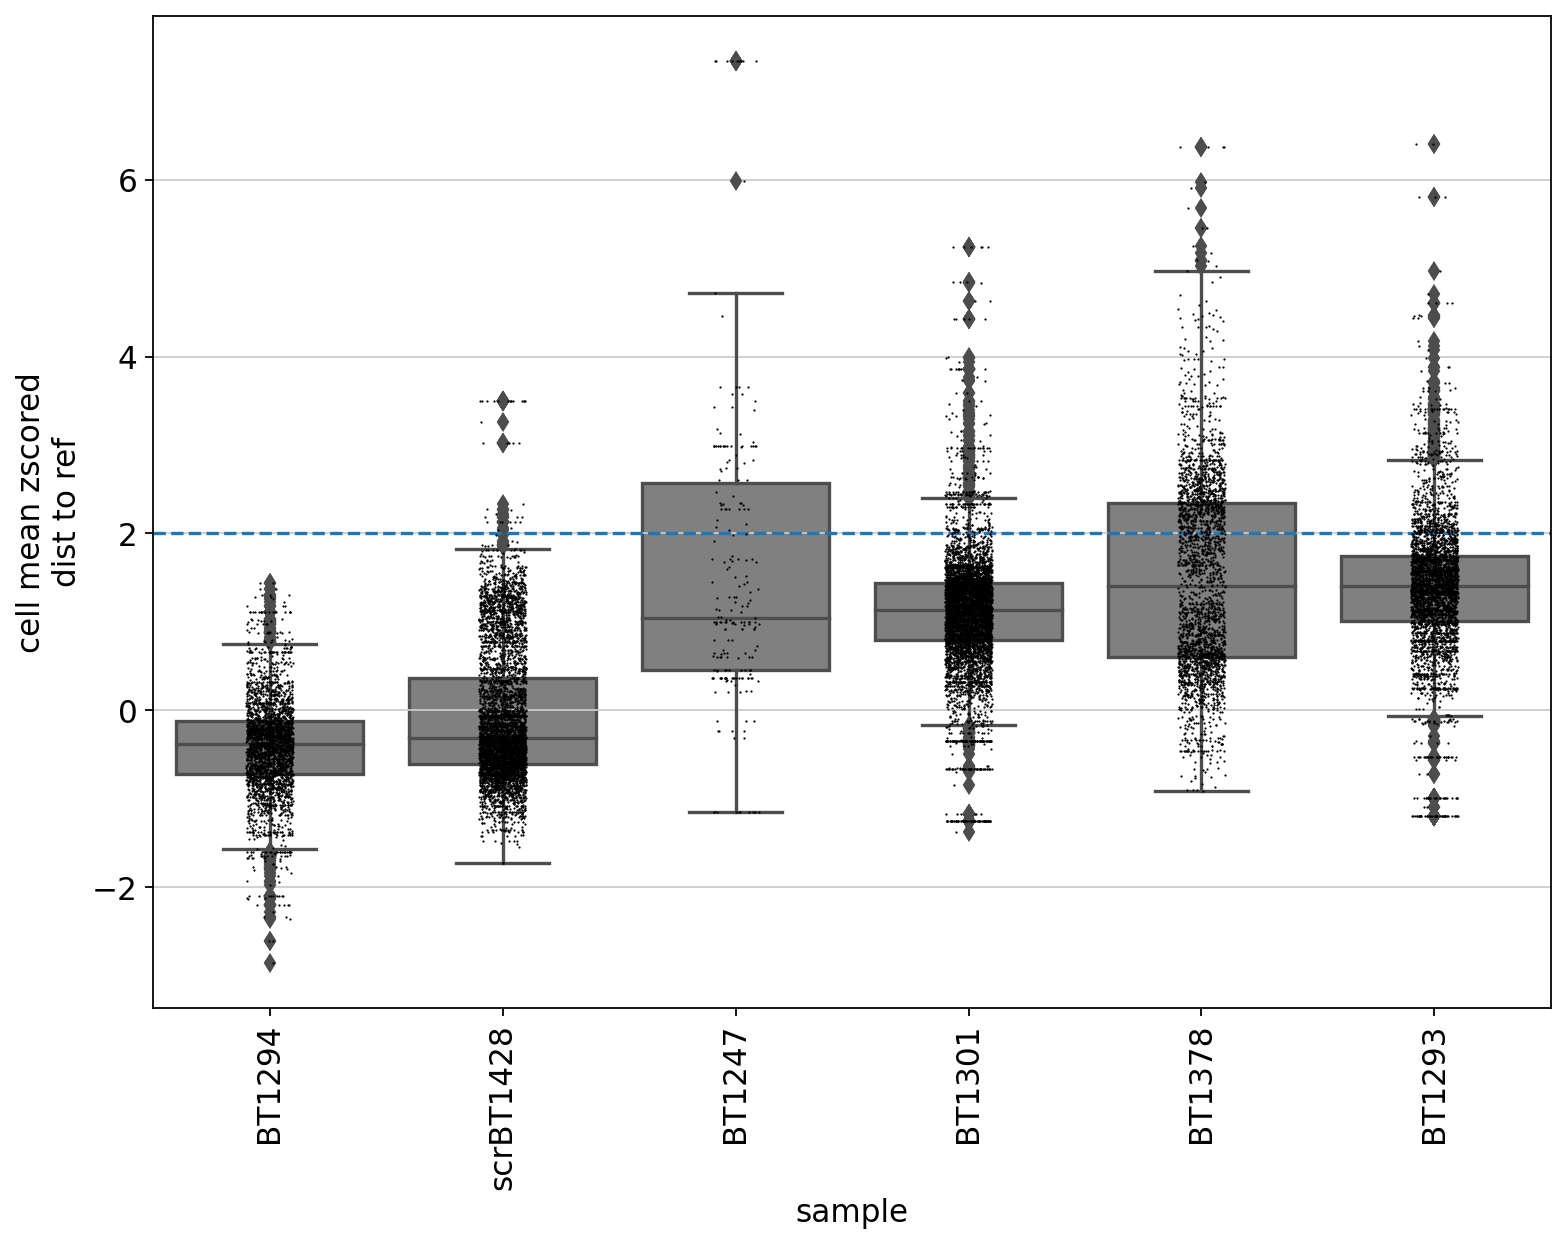

In [35]:
plotting.plot_sample_distances_to_reference_cell_level(results_healthy)

## Disease 1:

In [36]:
print(f"Subsetting query to condition {coi_disease}")
adata_disease = adata[
    (adata.obs[ref_q_key] == ref_cat) | (adata.obs[condition_key] == coi_disease)
].copy()

Subsetting query to condition Tumor


In [37]:
print(
    "number of query samples left:",
    len(
        adata_disease.obs.loc[
            adata_disease.obs[ref_q_key] == query_cat, "sample"
        ].unique()
    ),
)

number of query samples left: 26


In [38]:
adata.shape

(667754, 30)

In [39]:
adata_disease.shape

(643665, 30)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


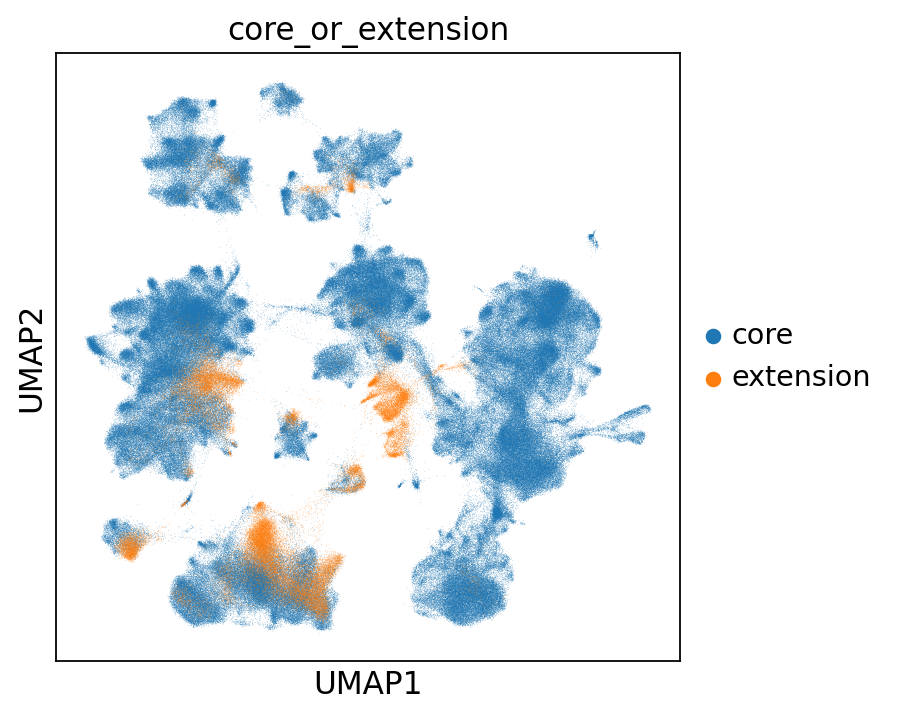

In [40]:
sc.pl.umap(adata_disease, color=ref_q_key)

#### run MapQC:

In [41]:
query_cell_idc_disease = np.where(adata_disease.obs[ref_q_key] == query_cat)[0].tolist()
random.seed(0)
center_cell_idc_disease = random.sample(query_cell_idc_disease, k=n_nhoods)
center_cells_disease = np.array(
    adata_disease.obs.iloc[center_cell_idc_disease, :].index
)

In [42]:
results_disease = mapqc.mapQC_results(
    adata=adata_disease,
    center_cells=center_cells_disease,
    k=k,
    emb_key=emb_key,
    ref_q_key=ref_q_key,
    ref_cat=ref_cat,
    query_cat=query_cat,
    batch_key=batch_key,
    exclude_same_batch_for_ref_samples=True,
    use_adaptive_k=True,
    max_k=max_k,
    # min_n_samples_q=1, # NOTE THAT THIS IS NOT THE DEFAULT AND SHOULD ONLY BE SET SO LOW IF NECESSARY
)

In [43]:
results_disease.calculate_sample_dists_to_ref_samples()

300it [03:10,  1.58it/s]
../../../mapqc/mapqc.py:199: RuntimeWarning: Mean of empty slice
  self.mean_sample_dists_to_ref = np.nanmean(self.intersample_distances, axis=0)
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1577: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,
../../../mapqc/mapqc.py:224: RuntimeWarning: Mean of empty slice
  nhood_ref_mean_dists = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1872: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


96% of neighborhoods passed filtering. (For more details, see [mapqc_object]._nhood_filtered)


In [44]:
results_disease._nhood_filtered.value_counts()

pass                                                287
too few query samples                                 8
too few reference samples from different batches      3
too few reference samples                             2
dtype: int64

In [45]:
results_disease.calculate_nhood_statistics(q=66)

77% of neighborhoods that passed filtering are below the significance threshold alpha=0.05.
For 39% of filtered neighborhoods, >34% of samples are more than two standard deviations above the mean distance from the reference.
16% of query samples (4 sample(s)) consistently do not mix well with the reference.
If these are control samples, consider removing them from the query and re-mapping.
For more information, check .sample_median_dist_to_ref_across_nhoods
or run plotting.plot_sample_distances_to_reference.


../../../mapqc/mapqc.py:364: RuntimeWarning: Mean of empty slice
  mean_zscored_q_dist_to_ref = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1217: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a, func=_nanmedian, keepdims=keepdims,
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1577: RuntimeWarning: All-NaN slice encountered
  result = np.apply_along_axis(_nanquantile_1d, axis, a, q,


In [47]:
results_disease.calculate_cell_statistics_using_sample_level_results_per_nhood()

Percentage of query cells showing low sample-mixing: 31.41.


### Plot

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


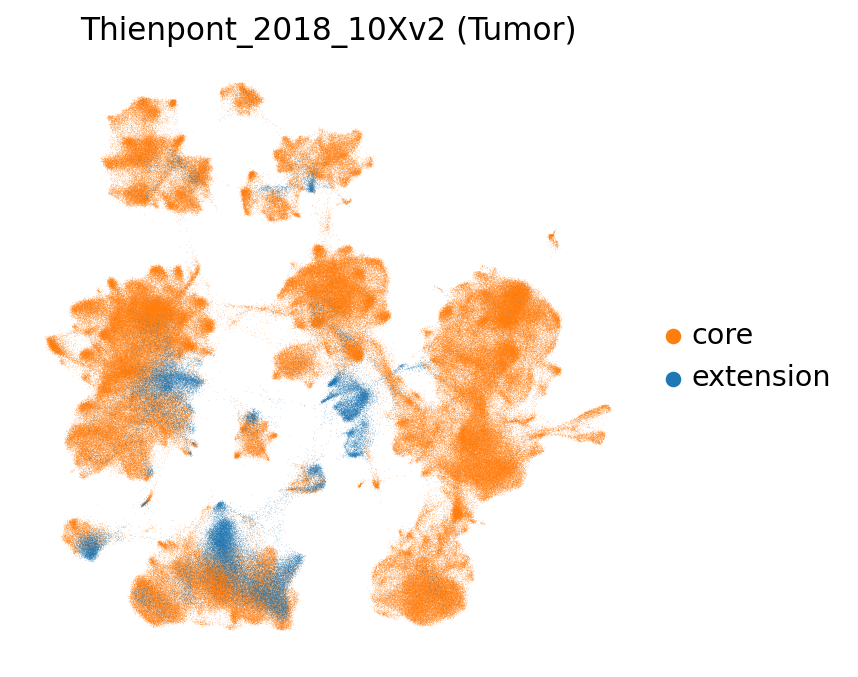

In [48]:
sc.pl.umap(
    results_disease.adata,
    color=ref_q_key,
    palette={
        results_disease.ref_cat: "tab:orange",
        results_disease.query_cat: "tab:blue",
    },
    title=f"{query_batch} ({coi_disease})",
    frameon=False,
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


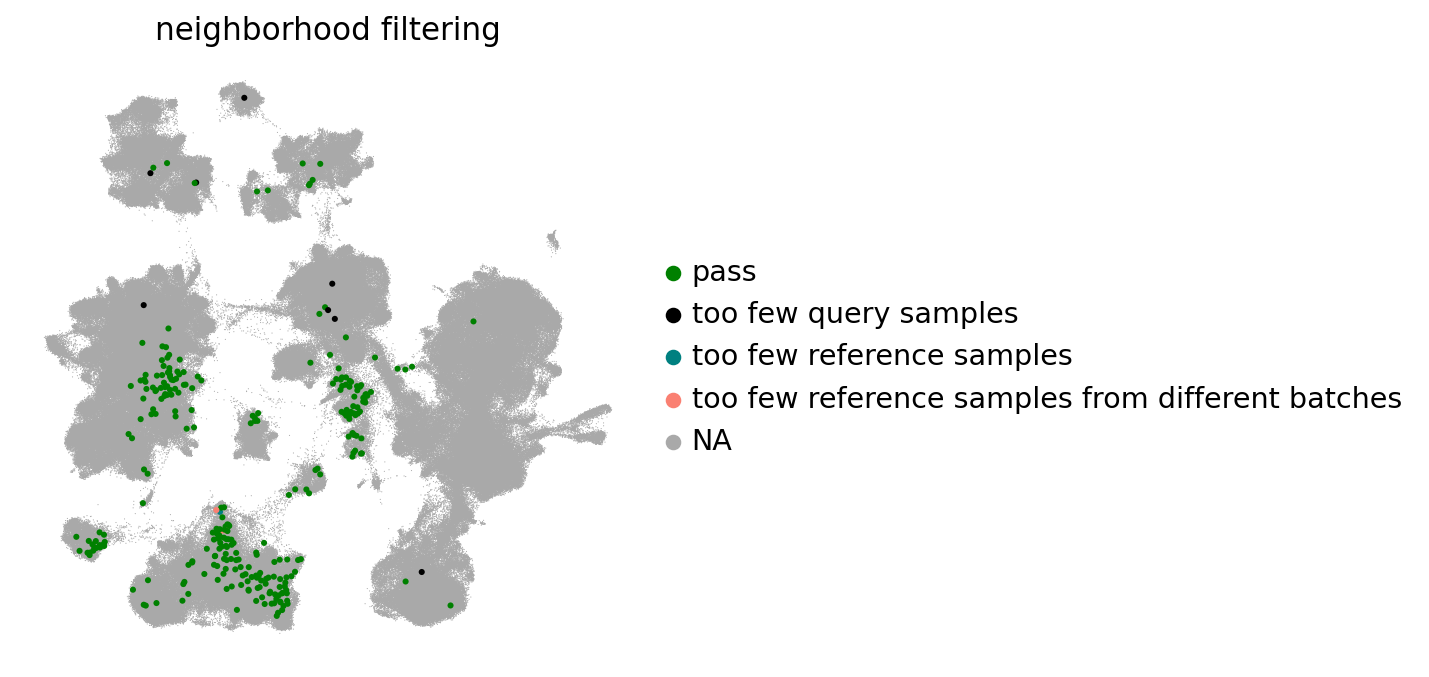

In [49]:
plotting.plot_umap_filtering_info(results_disease)

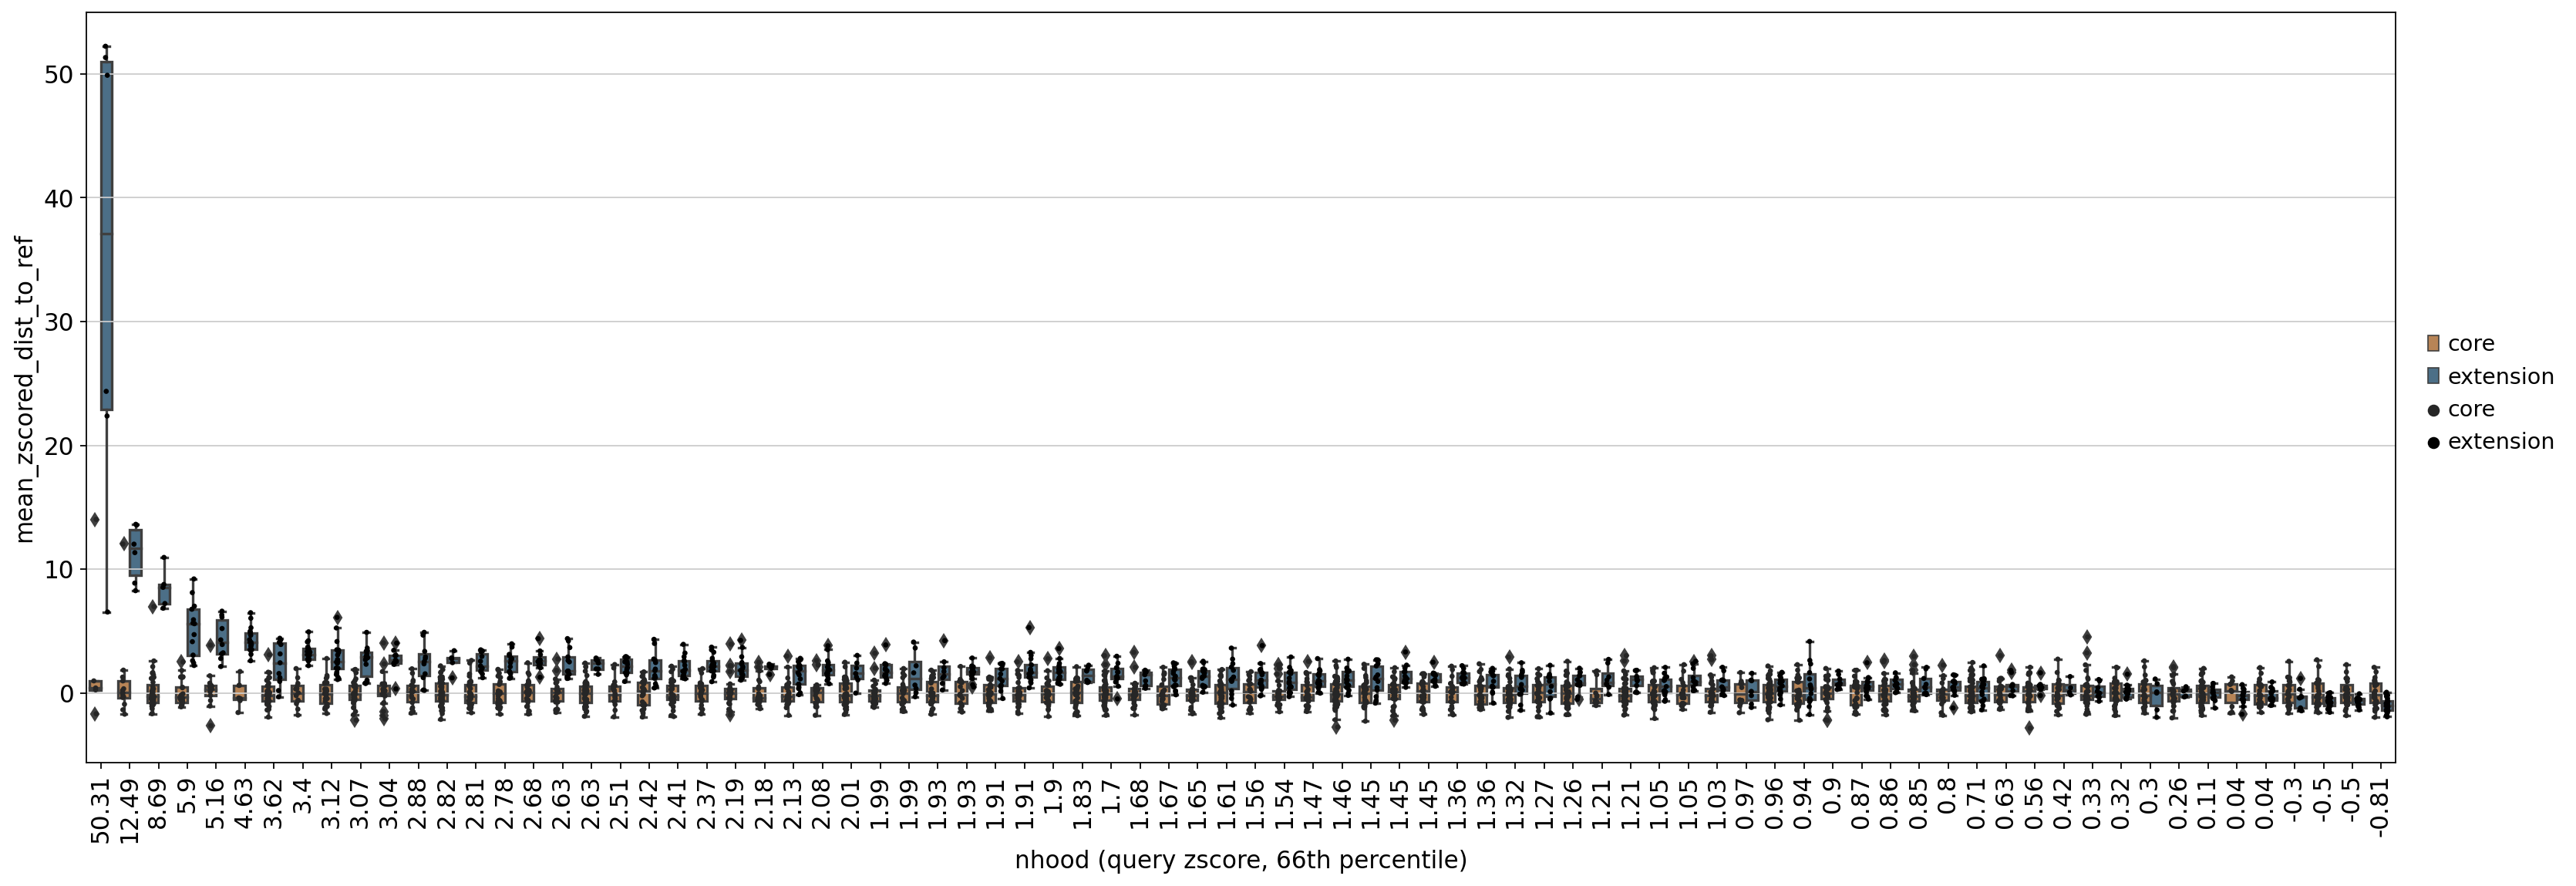

In [50]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(
    results_disease, use_zscored_dists=True
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


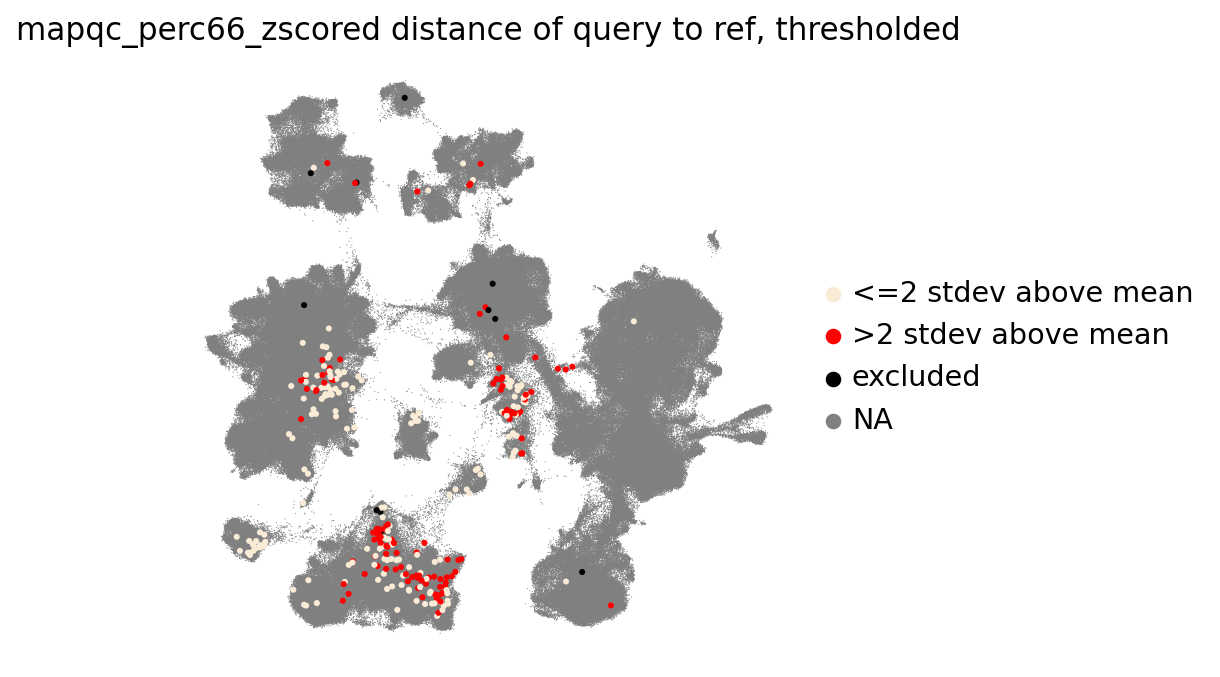

In [51]:
plotting.plot_umap_zscored_q_dist_to_ref(results_disease, color_by="percq_zscore>2")

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


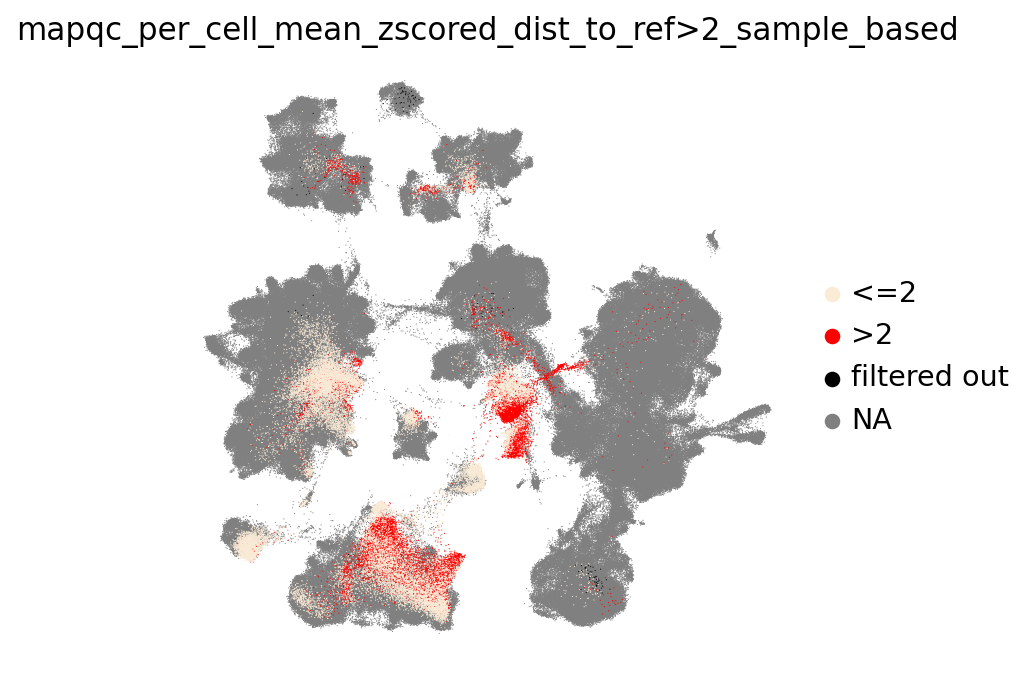

In [52]:
plotting.plot_umap_cell_level_results(results_disease, size=1)

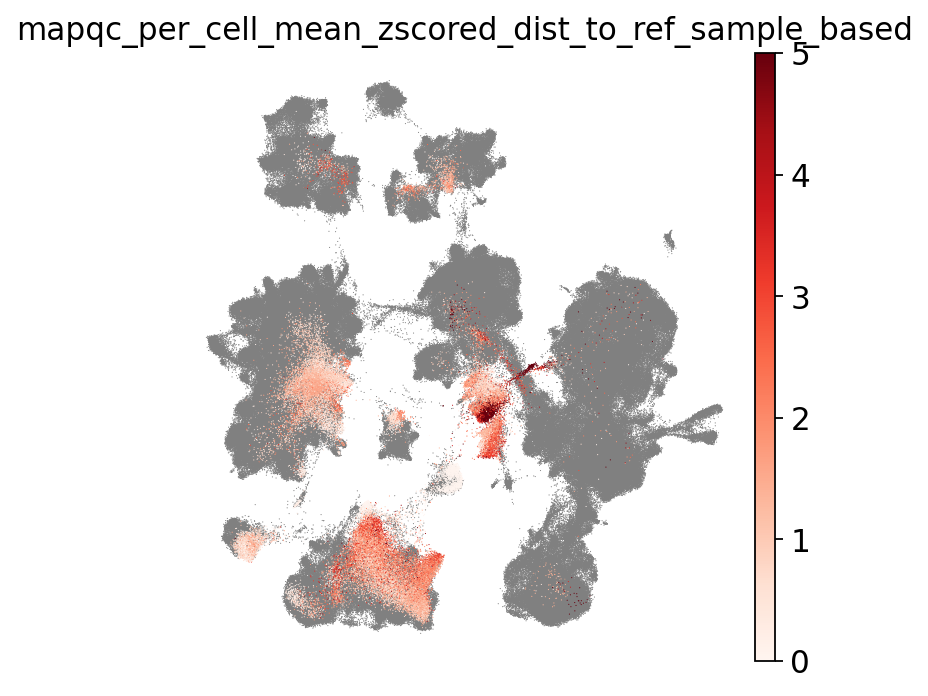

In [53]:
plotting.plot_umap_cell_level_results(
    results_disease, size=1, color_by="zscore", vmin=0, vmax=5
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


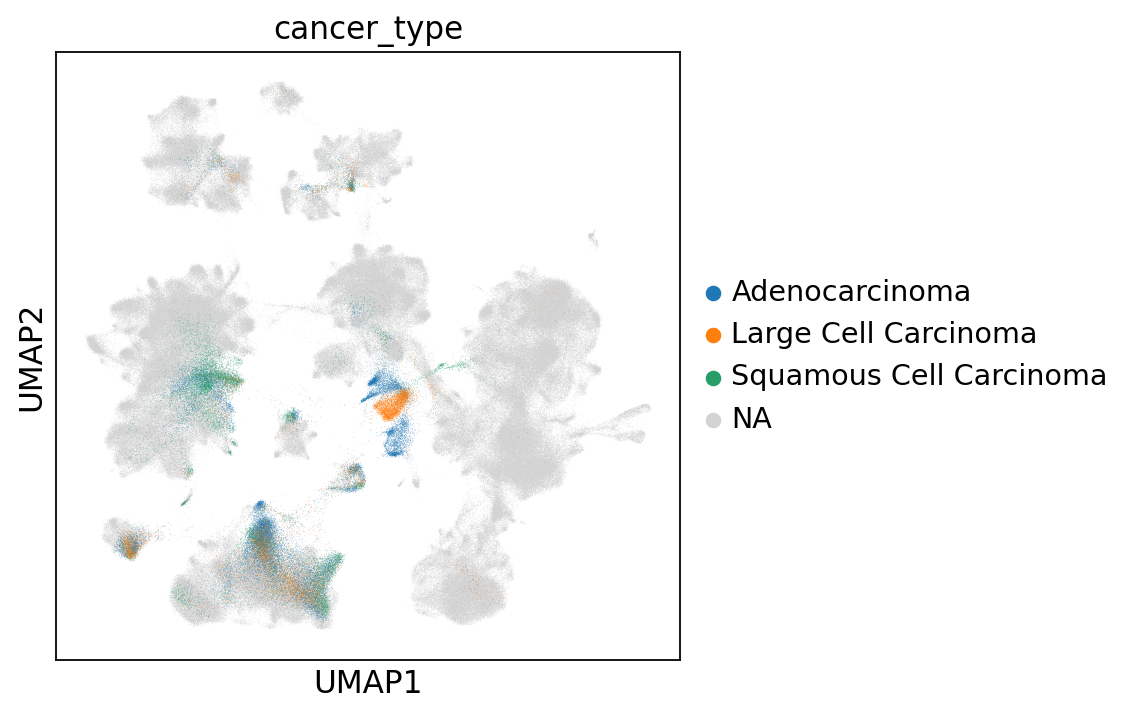

In [55]:
sc.pl.umap(adata_disease, color="cancer_type")

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


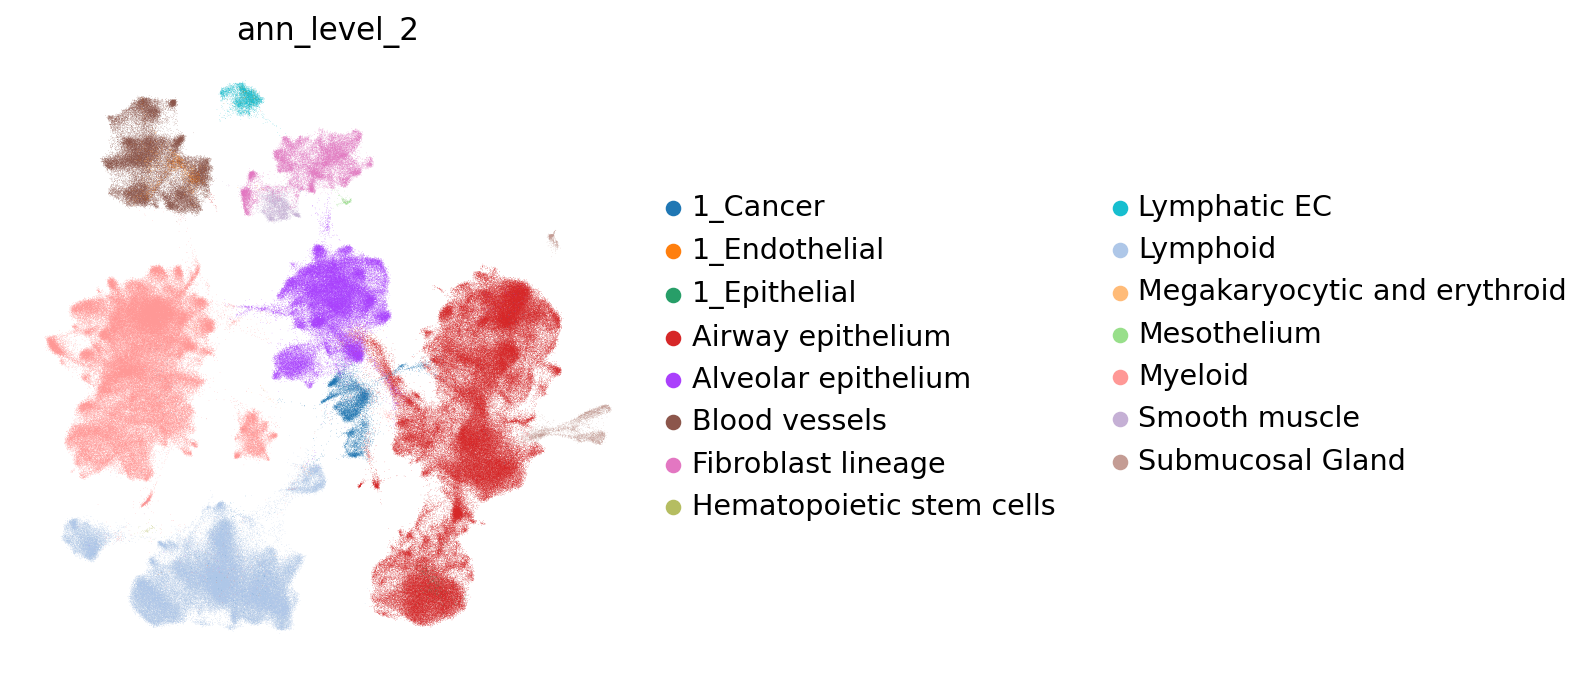

In [56]:
sc.pl.umap(adata_disease, color="ann_level_2", frameon=False)

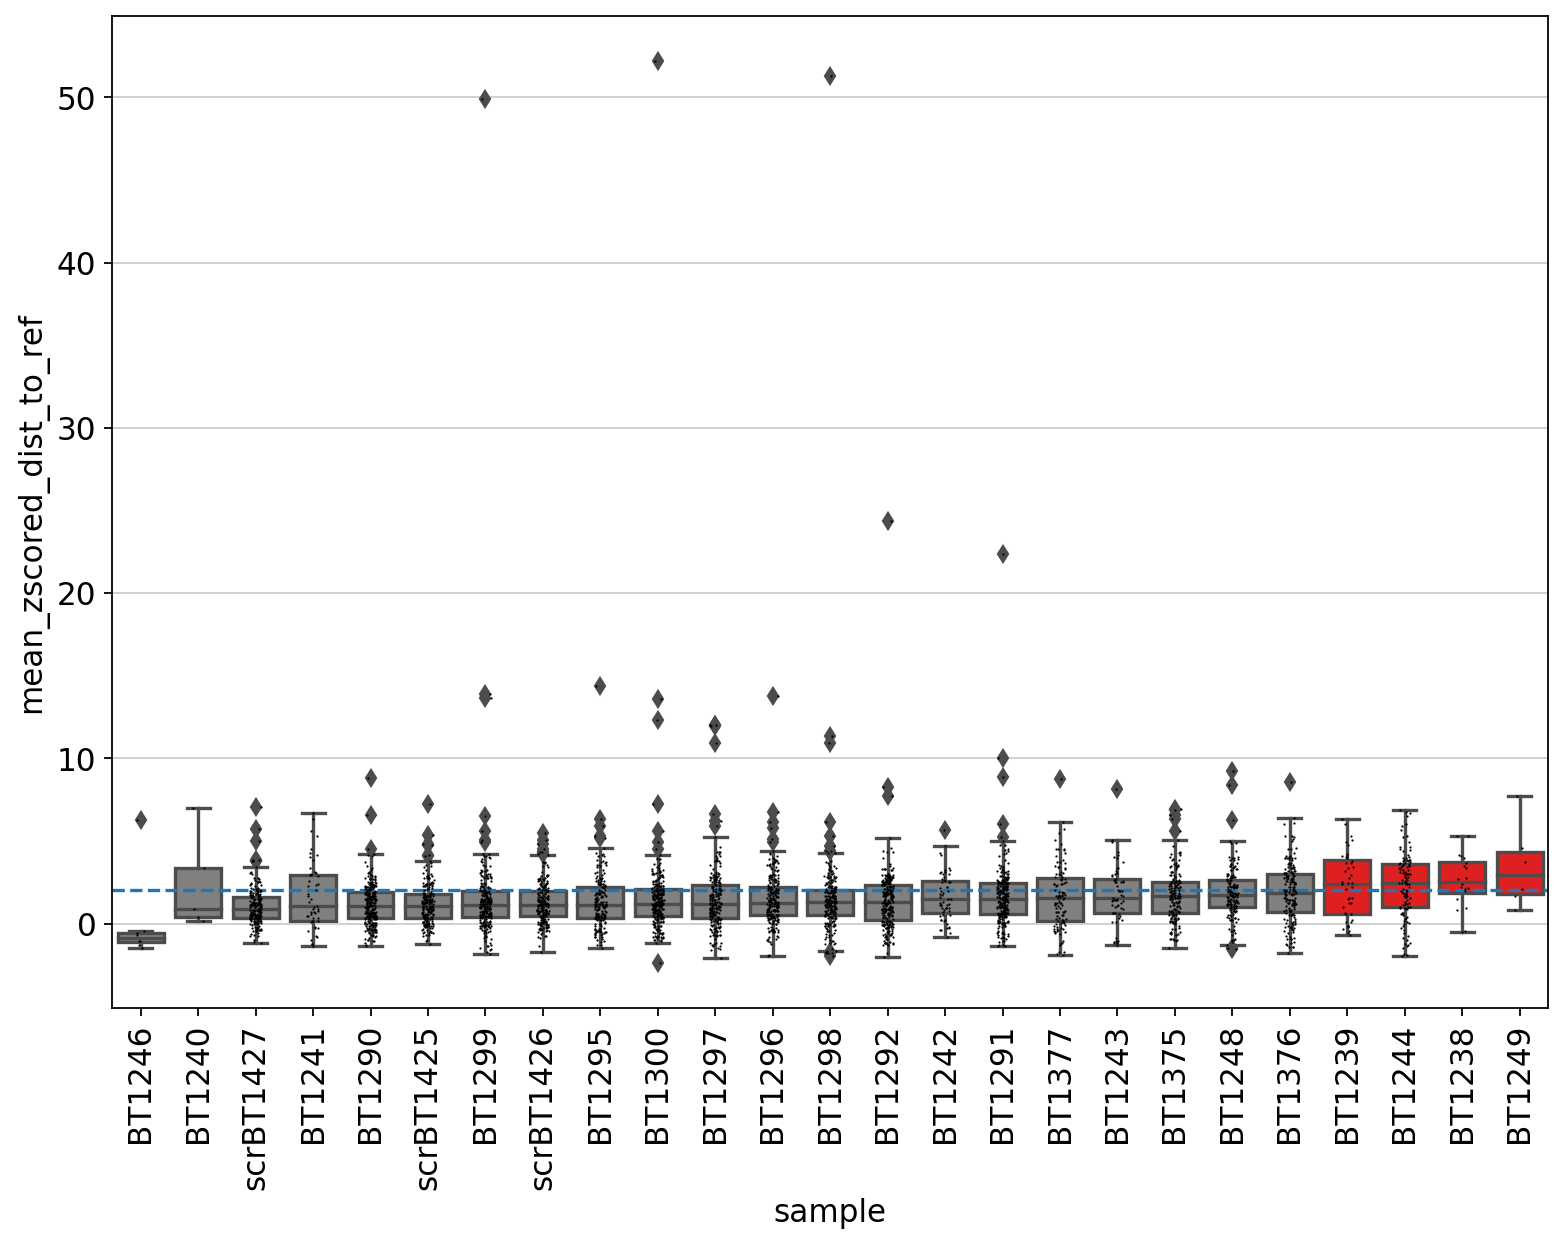

In [57]:
plotting.plot_sample_distances_to_reference(results_disease)

In [58]:
adata_disease.obs.groupby("sample").agg(
    {"cancer_type": "first", "subject_ID": "first"}
).dropna(axis=0, how="any")

,cancer_type,subject_ID
sample,,
BT1238,Squamous Cell Carcinoma,lambrechts_1
BT1239,Squamous Cell Carcinoma,lambrechts_1
BT1240,Squamous Cell Carcinoma,lambrechts_1
BT1241,Squamous Cell Carcinoma,lambrechts_1
BT1242,Squamous Cell Carcinoma,lambrechts_1
BT1243,Squamous Cell Carcinoma,lambrechts_1
BT1244,Squamous Cell Carcinoma,lambrechts_2
BT1245,Squamous Cell Carcinoma,lambrechts_2
BT1246,Squamous Cell Carcinoma,lambrechts_2


/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


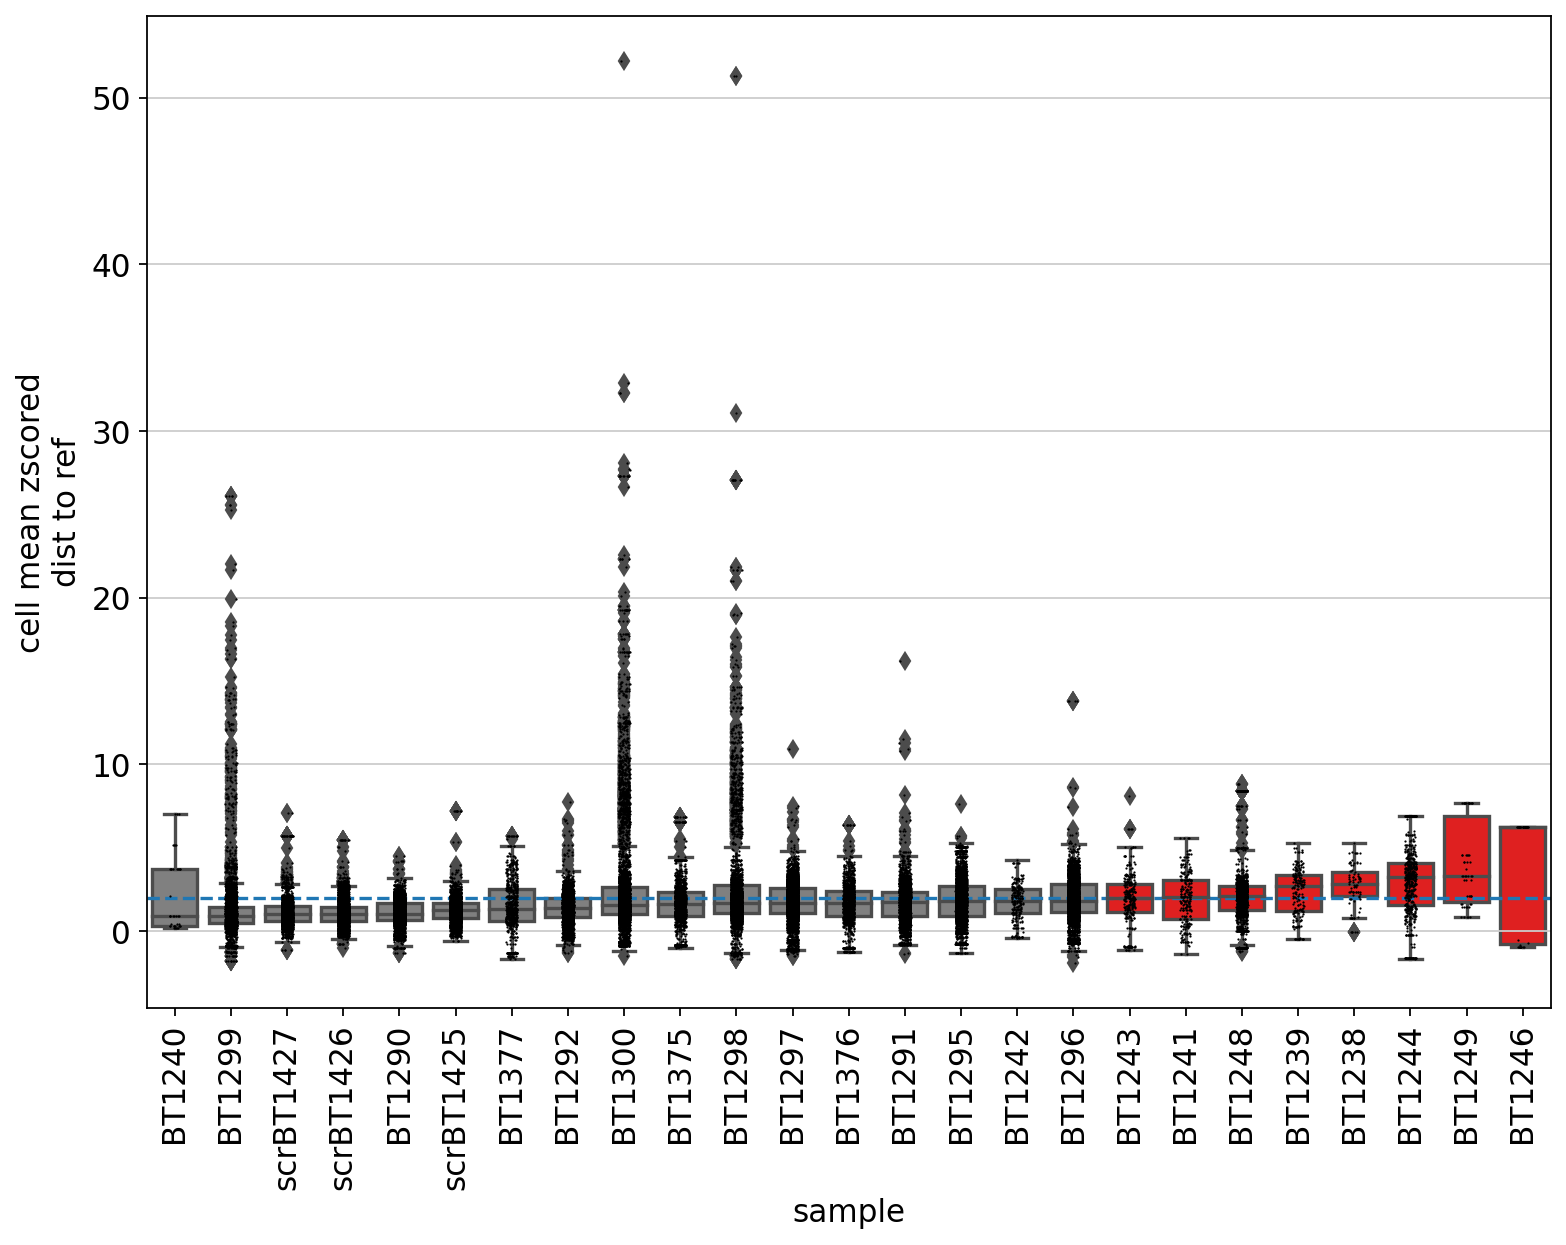

In [59]:
plotting.plot_sample_distances_to_reference_cell_level(results_disease)

### Store results:

In [ ]:
import pickle

In [ ]:
dir_mapped_results

In [ ]:
with open(f"{dir_mapped_results}/mapqc_results_healthy.pkl", 'wb') as outp:
    pickle.dump(results_healthy, outp, pickle.HIGHEST_PROTOCOL)
with open(f"{dir_mapped_results}/mapqc_results_disease.pkl", 'wb') as outp:
    pickle.dump(results_disease, outp, pickle.HIGHEST_PROTOCOL)